In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os, shutil

zip_path = "/content/drive/MyDrive/IP102.zip"   # 👈 your dataset zip
extract_path = "/content/IP102"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Files extracted to:", extract_path)

Mounted at /content/drive
Files extracted to: /content/IP102


In [ ]:
images_dir = os.path.join(extract_path, "IP102/JPEGImages")
ann_dir = os.path.join(extract_path, "IP102/Annotations")
output_dir = "/content/IP102_YOLO"
labels_dir = os.path.join(output_dir, "labels_yolo")
os.makedirs(labels_dir, exist_ok=True)

In [ ]:
import xml.etree.ElementTree as ET

fixed_count = 0
skipped_files = 0
valid_xml_files = []

for ann_file in os.listdir(ann_dir):
    if not ann_file.endswith(".xml"):
        continue
    path = os.path.join(ann_dir, ann_file)
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    # Keep only the first <annotation> block if multiple
    if content.count("<annotation") > 1:
        start = content.find("<annotation")
        end = content.rfind("</annotation>") + len("</annotation>")
        content = content[start:end]
        fixed_count += 1

    content = content.strip()  # remove junk before/after

    try:
        tree = ET.ElementTree(ET.fromstring(content))  # test parse
        tree.write(path)
        valid_xml_files.append(ann_file)
    except ET.ParseError:
        print(f"❌ Skipping invalid XML: {ann_file}")
        skipped_files += 1

print(f"✅ Fixed {fixed_count} malformed XML files")
print(f"⚠️ Skipped {skipped_files} completely invalid XML files")
print(f"Valid XML files to process: {len(valid_xml_files)}")

❌ Skipping invalid XML: IP087000986.xml
✅ Fixed 1 malformed XML files
⚠️ Skipped 1 completely invalid XML files
Valid XML files to process: 18975


In [ ]:
classes = set()
for ann_file in valid_xml_files:
    tree = ET.parse(os.path.join(ann_dir, ann_file))
    root = tree.getroot()
    for obj in root.iter("object"):
        cls = obj.find("name").text
        classes.add(cls)

classes = sorted(list(classes))
print("Detected classes:", classes)
print("Number of classes:", len(classes))

Detected classes: ['0', '1', '10', '100', '101', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '5', '50', '51', '52', '53', '54', '55', '56', '57', '58', '6', '61', '62', '64', '65', '66', '67', '68', '69', '7', '70', '71', '72', '73', '74', '76', '77', '78', '79', '8', '81', '82', '83', '84', '85', '86', '87', '88', '89', '9', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99']
Number of classes: 97


In [ ]:
def convert_bbox(size, box):
    dw, dh = 1.0 / size[0], 1.0 / size[1]
    x = (box[0] + box[1]) / 2.0
    y = (box[2] + box[3]) / 2.0
    w, h = box[1] - box[0], box[3] - box[2]
    return (x*dw, y*dh, w*dw, h*dh)

for ann_file in valid_xml_files:
    tree = ET.parse(os.path.join(ann_dir, ann_file))
    root = tree.getroot()
    size = root.find("size")
    w, h = int(size.find("width").text), int(size.find("height").text)

    label_lines = []
    for obj in root.iter("object"):
        cls = obj.find("name").text
        if cls not in classes:
            continue
        cls_id = classes.index(cls)
        xmlbox = obj.find("bndbox")
        b = (float(xmlbox.find("xmin").text), float(xmlbox.find("xmax").text),
             float(xmlbox.find("ymin").text), float(xmlbox.find("ymax").text))
        bb = convert_bbox((w,h), b)
        label_lines.append(f"{cls_id} {' '.join([str(a) for a in bb])}")

    if label_lines:  # only create label if objects exist
        label_file = os.path.join(labels_dir, ann_file.replace(".xml", ".txt"))
        with open(label_file, "w") as f:
            f.write("\n".join(label_lines))

In [ ]:
train_dir = os.path.join(output_dir, "train")
val_dir = os.path.join(output_dir, "val")
for split in ["train", "val"]:
    os.makedirs(os.path.join(output_dir, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(output_dir, split, "labels"), exist_ok=True)

# Only use images that have labels
all_images = [f.replace(".txt", ".jpg") for f in os.listdir(labels_dir)]

from sklearn.model_selection import train_test_split
train_imgs, val_imgs = train_test_split(all_images, test_size=0.1, random_state=42)

def move_files(file_list, split):
    for img in file_list:
        lbl_file = img.replace(".jpg", ".txt")
        shutil.copy(os.path.join(images_dir, img), os.path.join(output_dir, split, "images", img))
        shutil.copy(os.path.join(labels_dir, lbl_file), os.path.join(output_dir, split, "labels", lbl_file))

move_files(train_imgs, "train")
move_files(val_imgs, "val")

print("✅ Dataset ready.")
print("Train images:", len(os.listdir(os.path.join(train_dir, "images"))))
print("Val images:", len(os.listdir(os.path.join(val_dir, "images"))))

✅ Dataset ready.
Train images: 17077
Val images: 1898


In [ ]:
yaml_path = os.path.join(output_dir, "data.yaml")
with open(yaml_path, "w") as f:
    f.write(f"""
path: {output_dir}
train: train/images
val: val/images

nc: {len(classes)}
names: {classes}
""")
print("✅ YAML created at:", yaml_path)

✅ YAML created at: /content/IP102_YOLO/data.yaml


In [ ]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 37.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo11n.pt")  # YOLOv11 nano

model.train(
    data=yaml_path,
    epochs=25,
    imgsz=224,
    batch=32,
    workers=2,
    device="cuda"  # or "cpu"
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.203 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IP102_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=Fal

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 51, 52, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80,
       81, 82, 83, 84, 85, 86, 87, 89, 90, 91, 92, 93, 94, 95, 96])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fde66297c80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,   

In [ ]:
!find /content -name best.pt

/content/runs/detect/train/weights/best.pt



image 1/1 /content/IP102/IP102/JPEGImages/IP102003416.jpg: 640x576 2 101s, 88.5ms
Speed: 5.5ms preprocess, 88.5ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 576)
Results saved to /content/runs/detect/predict


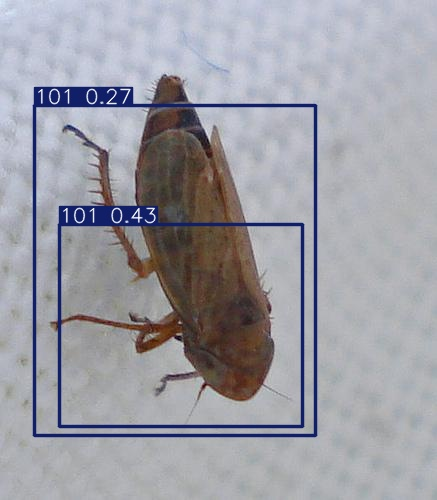

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
import os

# Load your trained model
model = YOLO("/content/runs/detect/train/weights/best.pt")  # path to your best.pt

# Specify the image path
img_path = "/content/IP102/IP102/JPEGImages/IP102003416.jpg"

# Run inference
results = model.predict(source=img_path, save=True, imgsz=640, conf=0.25)

# Get the correct save directory from results
save_dir = results[0].save_dir  # YOLO automatically sets this to 'predict', 'predict2', etc.

# Build the saved image path
saved_img_path = os.path.join(save_dir, os.path.basename(img_path))

# Display the saved image with detections
display(Image(filename=saved_img_path))

In [ ]:
import shutil
save_dir = "/content/IP102_YOLO/runs/detect/val_results"

# Remove if it exists
if os.path.exists(save_dir):
    shutil.rmtree(save_dir)
os.makedirs(save_dir, exist_ok=True)

# Now run inference
from ultralytics import YOLO
model = YOLO("/content/runs/detect/train/weights/best.pt")

results = model.predict(
    source="/content/IP102_YOLO/val/images",
    imgsz=224,
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    save_dir=save_dir,
    stream=False
)


WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1898 /content/IP102_YOLO/val/images/IP000000000.jpg: 160x224 1 0, 51.2ms
image 2/1898 /content/IP102_YOLO/val/images/IP000000003.jpg: 192x224 1 0, 49.3ms
image 3/1898 /content/IP102_YOLO/val/images/IP000000031.jpg: 160x224 (no detections), 10.5ms
image 4/1898 /content/IP102_YOLO/val/images/IP000000077.jpg: 192x224 2 0s, 8.2ms
image 5/1898 /content/IP102_YOLO/val/images/IP000000257.jpg: 160x224 1 0, 9.3ms
image 6/1898 /content/IP102_YOLO/val/ima

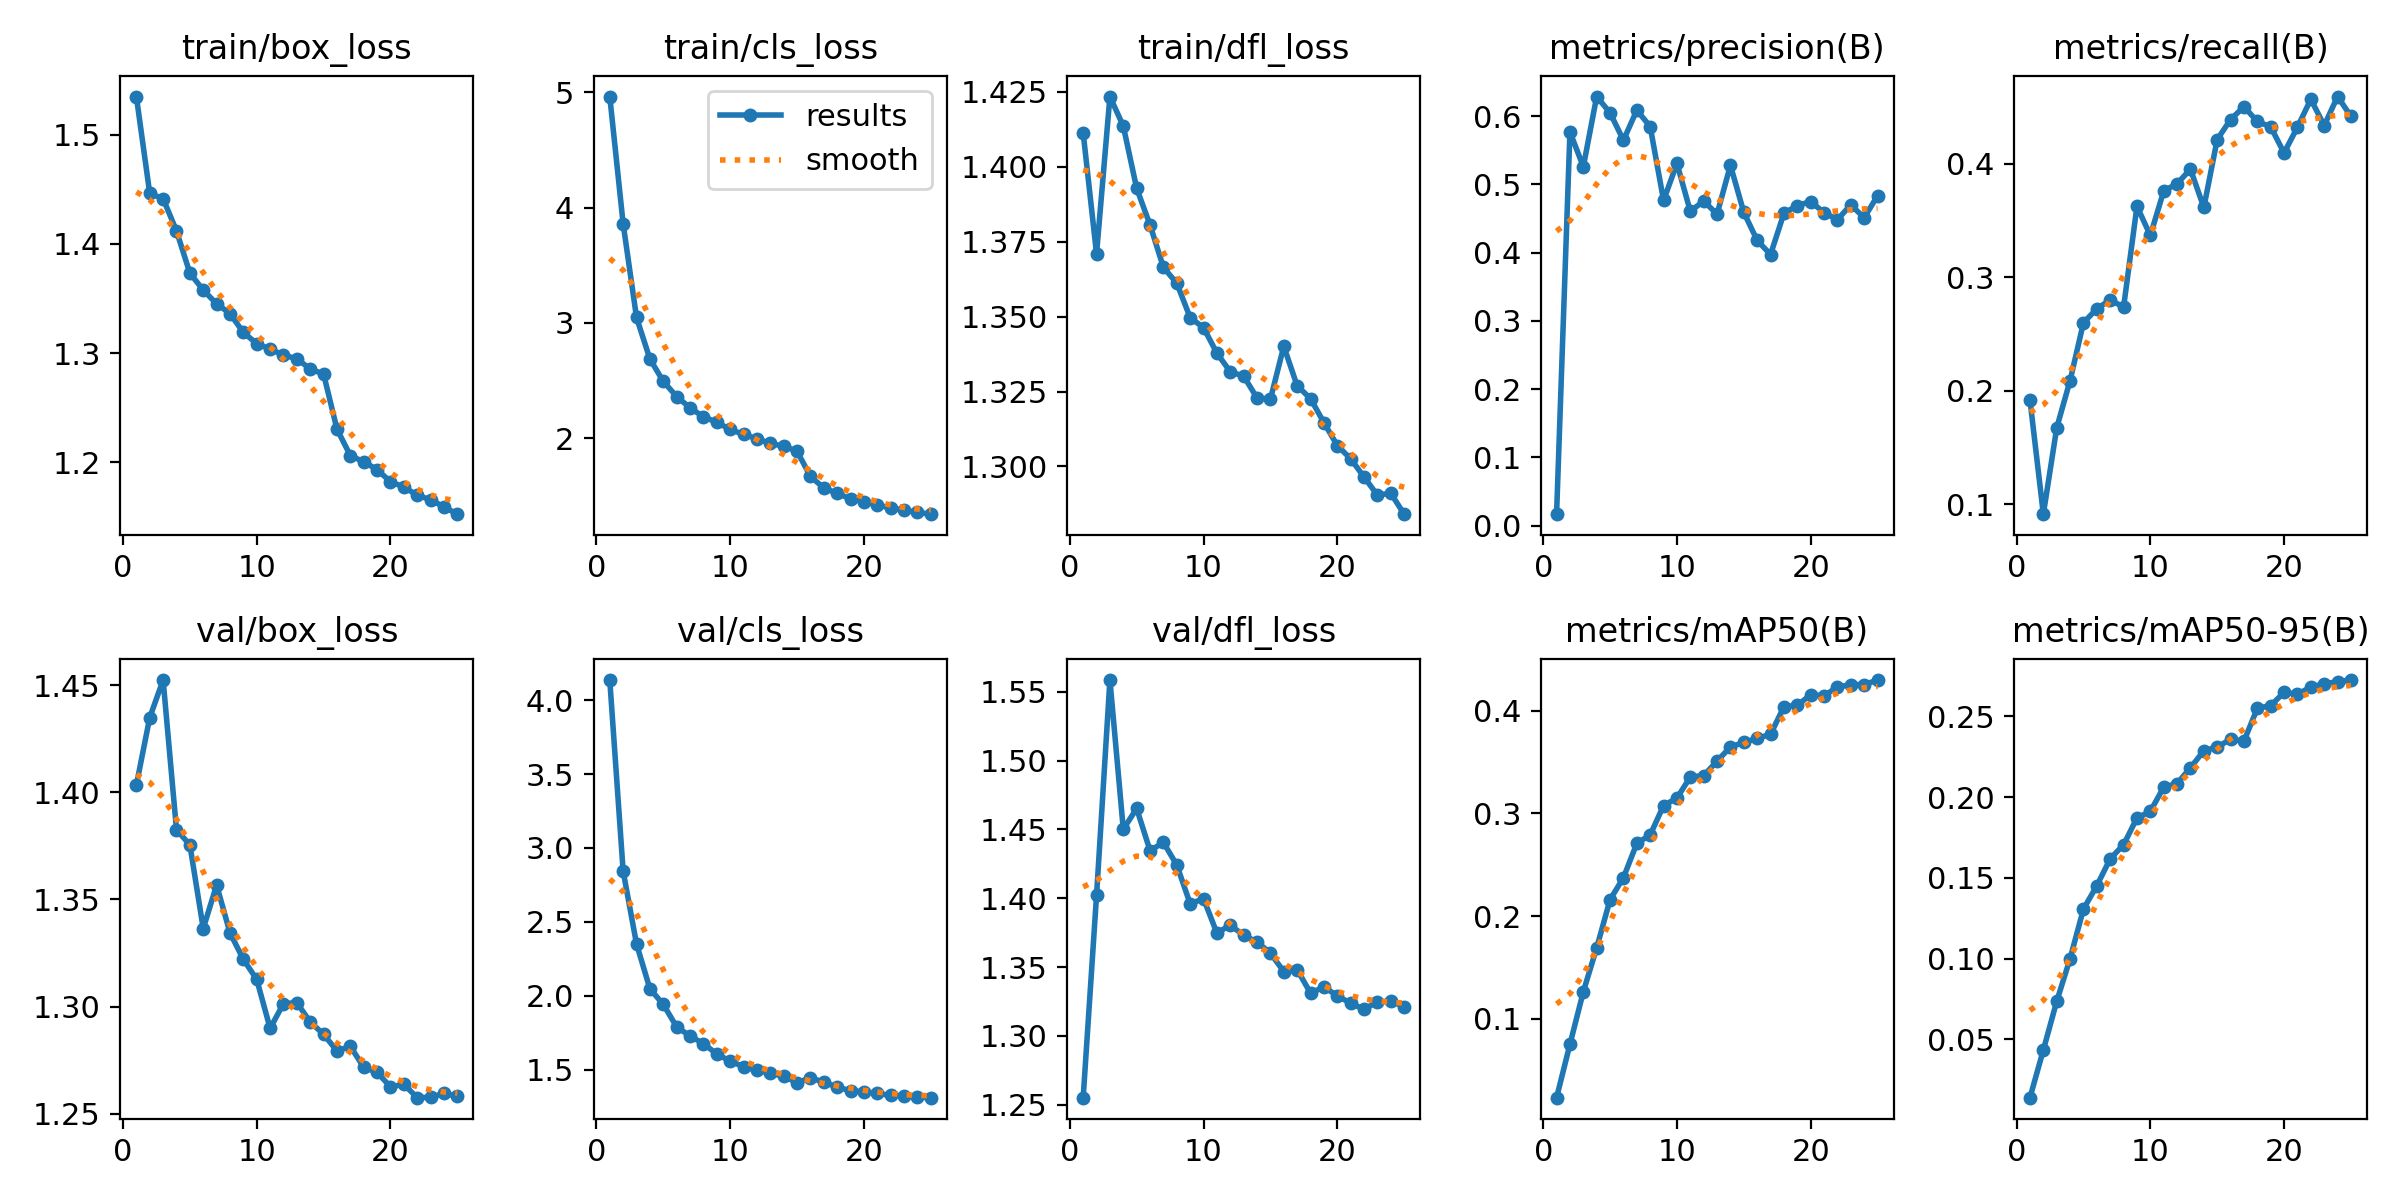

In [ ]:
from IPython.display import Image, display
import os

# Path to the training results folder
train_run_dir = "/content/runs/detect/train"

# Path to metrics graph
results_png = os.path.join(train_run_dir, "results.png")

# Display
if os.path.exists(results_png):
    display(Image(filename=results_png, width=800))
else:
    print("❌ results.png not found in:", train_run_dir)